# Board2Notes — the project story

**Start here to explain our work to teammates.** This overview uses selected saved results and images. Running it starts no model loading, training, OCR inference or downloads.

Our contribution is adapting a pretrained whiteboard-handwriting recognizer through justified comparisons, diagnosing its inputs, and preparing a usable OCR application. We did not invent HGNetV2 or demonstrate that every attempted change helps.

**Reading route:** problem → recognizer experiments → error investigation → actual photo pipeline → deployment status.

The detailed notebooks are linked in `01_detailed_evidence/`. This overview reflects the reviewed project record as of **9 November 2026**.

## 1. What problem are we solving?

A student photographs handwritten whiteboard notes. The OCR system needs to locate the writing and transcribe it into editable text. Structured notes and slides are later team components; the current package demonstrates OCR.

The professor asked us to investigate and adapt PaddleOCR beyond limited image preprocessing. We therefore examined its representation and training, and measured each change against a defined baseline.

The current application uses two models: **pretrained PP-OCRv5_mobile_det** finds boxes; **S1**, our fine-tuned PP-OCRv5_server_rec recognizer, reads extracted crops. Grouping, quad cropping and ordering are pipeline code between them.

In [1]:
from pathlib import Path
from collections import defaultdict
import csv, json, html, base64, re
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

roots=[q for p in [Path.cwd(),*Path.cwd().parents] for q in (p,p/'Assignment')]
A=next(p for p in roots if (p/'PROJECT_PROGRESS.md').is_file() and (p/'results_versions_2x2/results/predictions.csv').is_file())
def rows(path):
    with path.open(newline='',encoding='utf-8-sig') as f:return list(csv.DictReader(f))
def table(headers,data):
    e=lambda x:html.escape(str(x))
    display(HTML('<table style="border-collapse:collapse"><tr>'+''.join('<th style="padding:8px;text-align:left">'+e(h)+'</th>' for h in headers)+'</tr>'+''.join('<tr>'+''.join('<td style="padding:8px;border-bottom:1px solid #ddd">'+e(x)+'</td>' for x in row)+'</tr>' for row in data)+'</table>'))
def average(xs):
    xs=list(xs)
    if not xs:raise ValueError('Missing saved comparison')
    return sum(xs)/len(xs)
v=rows(A/'results_versions_2x2/results/predictions.csv')
def cer(data,model,st):return average(float(r['cer']) for r in data if r['model']==model and r['set']==st)
print('Project:',A)
print('Saved results only. Evidence notebooks remain in their original locations.')

Project: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment
Saved results only. Evidence notebooks remain in their original locations.


## 2. Investigate the recognizer, not just the photograph

The HGNetV2 CNN extracts visual features. Final pooling compresses them into a horizontal sequence. The SVTR neck processes relationships between positions, and the CTC head predicts character/blank probabilities.

The original training pooling forced 40 sequence positions. In the tested wide-input setting, our adaptation made training width follow the image, matching the reading geometry. At input width 1024, the adapted sequence has 128 positions; wider inputs can have more. Positions are not pre-cut characters.

**P40/P128** are the controlled pooling comparison: same wide input, starting weights, fitting-label subset and training budget; the training pooling differs. This does not show that every correctly configured 40-position model fails, or independently prove the repeated-letter explanation.

[Detailed experiment and image examples: notebook 10](01_detailed_evidence/10_training_results_visual_explorer.ipynb).

Model,What changes,CNN crop CER,Held-out sentence CER
pretrained,Untouched pretrained recognizer,45.79%,30.93%
V2short,Our short-line training data,28.57%,5.81%
V3short,Short-line data + extra augmentation,25.83%,4.49%
V2,Our data including long lines,23.72%,2.38%
V3,Short/long data + extra augmentation,24.27%,2.65%
P40,"Wide input, original 40-position training pooling",93.88%,45.26%
P128,"Matched pooling pair, width-proportional training pooling",26.60%,4.55%


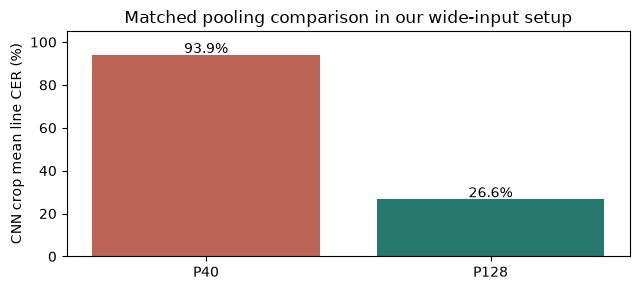

In [2]:
chosen=['pretrained','V2short','V3short','V2','V3','P40','P128']
descriptions={'pretrained':'Untouched pretrained recognizer','V2short':'Our short-line training data','V3short':'Short-line data + extra augmentation','V2':'Our data including long lines','V3':'Short/long data + extra augmentation','P40':'Wide input, original 40-position training pooling','P128':'Matched pooling pair, width-proportional training pooling'}
table(['Model','What changes','CNN crop CER','Held-out sentence CER'],[[m,descriptions[m],f"{cer(v,m,'CNN test'):.2%}",f"{cer(v,m,'long sentences (held out)'):.2%}"] for m in chosen])
fig,ax=plt.subplots(figsize=(6.5,3))
vals=[100*cer(v,m,'CNN test') for m in ['P40','P128']]
ax.bar(['P40','P128'],vals,color=['#bd6555','#26786c'])
for i,y in enumerate(vals):ax.text(i,y+1,f'{y:.1f}%',ha='center')
ax.set_ylim(0,105);ax.set_ylabel('CNN crop mean line CER (%)');ax.set_title('Matched pooling comparison in our wide-input setup')
fig.tight_layout();plt.show()

**What we learned:** data and representation both matter. Augmentation did not help every setup. These early comparisons are single-seed results. The held-out sentence result uses 57 crop views of **seven distinct sentences in familiar handwriting**, not 57 independent writers or sentences. The CNN board also has few distinct texts. Read small differences cautiously.

The historical V1 checkpoint and IAM/configuration controls remain in notebook 10. They are not interchangeable with the controlled S0 baseline used next.

## 3. Test how the model learns

- **S0:** clean reference training data, excluding the 64 uncertain-writer teammate crops.
- **S1:** smaller learning rates in earlier backbone stages, allowing cautious adaptation of pretrained features.
- **S2:** focal CTC changes how easy/hard sequence losses contribute.
- **S3:** combines S1 and S2.
- **G0:** lets the deployed reader's CTC loss also update the backbone, instead of stopping its gradient before the backbone. The NRTR helper remains part of training.

These are training-strategy comparisons. The same optimizer remains Adam; we did not add SVTR layers. Two separately trained seeds help reveal variation, but do not establish performance over all possible seeds.

In [3]:
sg=rows(A/'results_strategies_s0s3/results/predictions.csv')
gg=rows(A/'results_guide_g0/results/predictions.csv')
def recipe_cer(base,st):
    data=gg if base=='G0' else sg
    return average(cer(data,base+s,st) for s in ('','s2'))
table(['Recipe','Whiteboard validation','CNN crops','Original JH/DS crops','IAM'],[[m]+[f'{recipe_cer(m,st):.2%}' for st in ['whiteboard val','CNN test','new writers','IAM val']] for m in ['S0','S1','S2','S3','G0']])
jy=rows(A/'whiteboard-ocr/outputs/jy_ocr_evaluation/predictions.csv')
table(['Jy original-crop confirmation','Two-seed mean line CER'],[[m,f"{average(float(r['cer']) for r in jy if r['model'] in (m,m+'s2')):.2%}"] for m in ['S0','S1','G0']])

Recipe,Whiteboard validation,CNN crops,Original JH/DS crops,IAM
S0,7.52%,25.50%,26.79%,23.89%
S1,7.09%,24.58%,24.93%,23.72%
S2,7.24%,24.87%,26.47%,26.53%
S3,7.19%,25.03%,25.97%,23.89%
G0,7.17%,25.70%,22.77%,27.15%


Jy original-crop confirmation,Two-seed mean line CER
S0,7.34%
S1,5.52%
G0,5.64%


**Decision:** none of S1–S3 or G0 established improvement under the original primary validation rule. S1 and G0 later improved on the reserved Jy collection under its recorded comparisons; neither is established as universally superior. S1 seed 1 remains the provisional application choice, based on the earlier validation selection—not on picking a lucky seed from Jy.

The original JH/DS crop results above are valid for those inputs. The following investigation shows why interpreting their entire error gap as handwriting difficulty was too strong. IAM deterioration is a measured trade-off.

[Full strategy results, uncertainty and examples: notebook 10, section 7b](01_detailed_evidence/10_training_results_visual_explorer.ipynb).

## 4. Diagnose the input before adding model capacity

Large background margins shrink the writing when the entire crop is resized to height 64. Sloped writing inside an upright rectangle can also occupy a tall box. We tested existing crops, safely tightened crops, straightened/recropped lines and width-matched stretching, keeping the readers frozen.

These tests improved recognition substantially. Stretching recovered similar gains in the primary comparison, supporting horizontal scale as an important contributor. It does not prove that slope never matters or establish equivalence between interventions. Some individual crops worsened.

[Frozen protocols, all readers, controls and regressions: notebook 14](01_detailed_evidence/14_crop_margin_diagnostic.ipynb).

In [4]:
margin=json.loads((A/'claude_margin_diagnostic_20261109/RESULTS.json').read_text())
straight=json.loads((A/'claude_margin_diagnostic_20261109/straighten/RESULTS_STRAIGHTEN.json').read_text())
m=margin['groups']['large margin'];q=straight['groups']['sloped']['S1avg']
table(['Diagnostic','Scope','Before','After'],[
 ['Margin removal, S1 seed 1',f"{m['n']} large-margin crops",f"{m['cer_original']:.2%}",f"{m['cer_tight']:.2%}"],
 ['Straighten + recrop, S1 seed average',f"{q['n']} sloped lines",f"{q['cer_T']:.2%}",f"{q['cer_R']:.2%}"],
 ['Width-matched stretching, S1 seed average','Same sloped lines',f"{q['cer_T']:.2%}",f"{q['cer_H']:.2%}"]])
print('These experiments use development crops and manually reviewed transformations, not a new deployed preprocessing stage.')

Diagnostic,Scope,Before,After
"Margin removal, S1 seed 1",51 large-margin crops,35.37%,6.25%
"Straighten + recrop, S1 seed average",40 sloped lines,24.85%,7.91%
"Width-matched stretching, S1 seed average",Same sloped lines,24.85%,7.42%


These experiments use development crops and manually reviewed transformations, not a new deployed preprocessing stage.


## 5. Check the actual full-photo path

We compared mobile and server detectors with S1 fixed. The server had no established overall page-CER gain on the 16 Jy photos under the recorded rule, with much higher measured detection cost on this Mac. The ordering diagnostic explains a large part of the page-error difference, but requires provisional answer-key geometry.

[Detector quality, cost and actual numbered boxes: notebook 15](01_detailed_evidence/15_full_photo_detector_comparison.ipynb).

Reading-order improvement is **deferred**, not absent from the investigation. Its intended convention still needs confirmation for the final notes/slide workflow.

In [5]:
det=json.loads((A/'whiteboard-ocr/outputs/detector_comparison/analysis/RESULTS.json').read_text())
table(['Detector on Jy, same S1','Actual page CER','GT-assisted reordered CER','Detection seconds/photo'],[[m,f"{det['page_CER'][m]:.2%}",f"{det['gt_reordered_CER'][m]:.2%}",f"{det['timing'][m]['detection s/photo (median)']:.2f}"] for m in ['mobile','server']])
jh=json.loads((A/'claude_jh_fullphoto_20261109/RESULTS.json').read_text());j=jh['summary']
table(['JH: same 59 matched lines, S1 seed 1','Mean line CER','Deleted characters'],[[k,f"{j['cer_'+k]:.2%}",j['D_'+k]] for k in ['original','tight','straightened','app']])

"Detector on Jy, same S1",Actual page CER,GT-assisted reordered CER,Detection seconds/photo
mobile,27.52%,5.64%,0.49
server,25.56%,5.16%,5.84


"JH: same 59 matched lines, S1 seed 1",Mean line CER,Deleted characters
original,21.14%,232
tight,16.43%,187
straightened,5.37%,68
app,0.87%,5


**The app already avoids most of the JH dataset-crop problem.** Its detector supplies tilted boxes and existing quad cropping produces wider, nearly horizontal inputs. The seven full photos also contain more source pixels than the dataset crops, so source detail and geometry are confounded.

The 0.87% number is **matched-line mean CER on 59 supplied lines from one development writer**. It excludes unmatched outputs and is not full-page accuracy. Both the JH result and Jy page result matter; they answer different questions.

[All seven photos, input tensors and every four-way line comparison: notebook 16](01_detailed_evidence/16_jh_full_photo_app_evaluation.ipynb).

Original dataset crop,Actual app crop
,
A btelts te o s s du f ing.,A botnet is a collection of zombies all used to do things

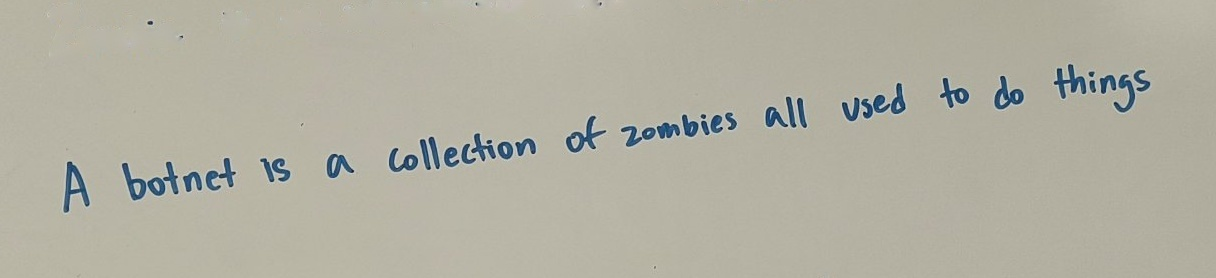
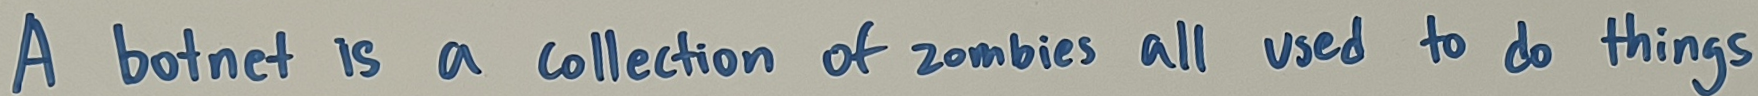

Same frozen reader; original crop CER: 64.91% app crop CER: 0.00%


In [6]:
case=next(r for r in jh['one_to_one'] if r['line']=='jhs__train__JH6.4.jpg')
def image_url(path):
    mime='image/png' if path.suffix=='.png' else 'image/jpeg'
    return 'data:'+mime+';base64,'+base64.b64encode(path.read_bytes()).decode()
orig=A/case['original']['file']
app=A/'whiteboard-ocr/outputs/jh_full_photos_app/crops'/case['app_files']['crop']
e=html.escape
display(HTML('<p><b>Same intended sentence:</b> '+e(case['label'])+'</p><table style="width:100%;table-layout:fixed"><tr><th>Original dataset crop</th><th>Actual app crop</th></tr><tr><td><img style="max-width:100%" src="'+image_url(orig)+'"></td><td><img style="max-width:100%" src="'+image_url(app)+'"></td></tr><tr><td style="padding:8px;overflow-wrap:anywhere">'+e(case['original']['text'])+'</td><td style="padding:8px;overflow-wrap:anywhere">'+e(case['app_text'])+'</td></tr></table>'))
print('Same frozen reader; original crop CER:',f"{case['original']['cer']:.2%}",'app crop CER:',f"{case['app']['cer']:.2%}")

## 6. Working configuration and deployment status

The current inference package contains **mobile detector → existing grouping/order → quad crop → S1 seed 1 → editable OCR text**, with model hashes, regression fixtures and deployment configuration. It does not contain the whole research archive.

The package integrity and saved Linux-versus-Mac regression comparisons have been checked. A fresh package environment on the Mac and an actual x86 container build remain separate verification milestones. Cloud hosting and fresh-photo confirmation are not complete. Do not describe packaging as completed cloud deployment.

The remaining confirmation should use genuinely fresh writers/photo groups with reviewed references fixed before scoring. Existing JH/DS and Jy evidence now informs development.

For the live demo, launch the package separately using `../board2notes_ocr_package/run_local.command` after its installation/verification steps. This notebook does not start a server.

## 7. How to present this work

1. Explain the task and the professor's requested shift toward model adaptation.
2. Show the controlled pooling comparison and one training-strategy result, including uncertainty.
3. Show the input-geometry example above: a failure was not automatically a model-capacity failure.
4. Explain the detector choice and the existing app crop path.
5. Demonstrate photo upload → boxes → editable text → export, then state deployment and evaluation limitations.

Keep the detailed evidence separate so the presentation stays readable. No experiment guarantees a rubric grade, universal superiority or population-wide handwriting performance.

[Main evidence folder](01_detailed_evidence/) · [Supporting evidence](02_supporting_evidence/) · [Earlier work](03_earlier_work/) · [Notebook guide](README.md) · [Project record](../PROJECT_PROGRESS.md)